# 01 — Visualiser les clips de mocap

Objectif : voir à quoi ressemblent les 56 clips du jeu **Locomotion** (Table 2 de l'article),
avant d'écrire quoi que ce soit d'autre.

On procède en quatre temps :
1. ouvrir un fichier `.pkl` sans risque ;
2. lire le squelette dans `humanoid.xml` ;
3. passer d'une frame (34 nombres) aux positions 3D des segments : la **cinématique directe** ;
4. animer quelques clips en GIF.

Les données doivent être dans `data/` (voir le README).

In [1]:
import pickle
import xml.etree.ElementTree as ET
from pathlib import Path

import numpy as np
import matplotlib
matplotlib.use("Agg")  # rendu hors écran : on affiche les GIF, pas des fenêtres
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data"
MOTIONS = DATA / "motions" / "humanoid"
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
print("Données :", DATA)

Données : /users/eleves-a/2023/roman.lendormy/mva/mva-robotics-project/data


## 1. Ouvrir un clip

Un fichier `.pkl` est un objet Python sérialisé. **Le charger avec `pickle.load` peut exécuter du code**
choisi par l'auteur du fichier. Nos fichiers ne contiennent que des types simples (dict, list, float) :
on utilise donc un `Unpickler` qui refuse d'importer quoi que ce soit (`find_class` lève une erreur).
Si un fichier essayait de faire autre chose, le chargement échouerait au lieu de l'exécuter.

In [2]:
class SafeUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        raise pickle.UnpicklingError(f"import interdit dans le pickle : {module}.{name}")


def load_clip(name):
    # name : chemin relatif à data/motions/humanoid, sans .pkl (ex. "long/humanoid_long_walk0")
    with open(MOTIONS / f"{name}.pkl", "rb") as f:
        clip = SafeUnpickler(f).load()
    frames = np.array(clip["frames"], dtype=float)
    nan_cols = np.where(np.isnan(frames).any(axis=0))[0]
    if len(nan_cols):
        print(f"  {name} : NaN dans les colonnes {nan_cols.tolist()} -> remplacés par 0")
        frames = np.nan_to_num(frames)
    return {"name": name, "fps": float(clip["fps"]), "loop": clip["loop_mode"], "frames": frames}


walk = load_clip("humanoid_walk")
print({k: v for k, v in walk.items() if k != "frames"}, "| frames :", walk["frames"].shape)
print("frame 0 :", np.round(walk["frames"][0], 2))

  humanoid_walk : NaN dans les colonnes [9, 10, 11] -> remplacés par 0
{'name': 'humanoid_walk', 'fps': 120.0, 'loop': 1} | frames : (125, 34)
frame 0 : [ 0.96  0.05  0.83  0.02  0.01 -0.05 -0.02  0.   -0.    0.    0.    0.
  1.34  0.24 -0.31  0.61 -0.99  0.32 -0.53 -0.69 -0.04 -0.5   0.05  0.16
  0.    0.02 -0.26 -0.03  0.23  0.11  0.29  0.04 -0.3   0.01]


Un clip est donc une suite de frames de **34 nombres**, échantillonnées à `fps` Hz.
Pour les interpréter, il faut le squelette.

## 2. Le squelette, lu dans `humanoid.xml`

Le fichier MJCF décrit un arbre de **corps** (`<body>`). Chaque corps a :
- une position `pos` dans le repère de son parent (l'« offset », fixe) ;
- 0, 1 ou 3 articulations `<joint type="hinge">` qui le relient à son parent.

MimicKit interprète ces articulations ainsi (fichier `mjcf_char_model.py` de MimicKit) :

| charnières | type | valeurs dans une frame |
|---|---|---|
| 0 | fixe (les mains) | aucune |
| 1 | révolution (genoux, coudes) | 1 angle autour de l'axe de la charnière |
| 3 (x, y, z) | sphérique | **exponential map** (3 nombres), pas des angles d'Euler |

Le premier corps (`pelvis`) est la racine : sa position et sa rotation dans le monde occupent
les 6 premières valeurs de la frame.

In [3]:
def load_skeleton(path):
    bodies = []

    def visit(elem, parent):
        joints = elem.findall("joint")
        axis = np.array([float(x) for x in joints[0].get("axis").split()]) if len(joints) == 1 else None
        kind = {0: "fixe", 1: "révolution", 3: "sphérique"}[len(joints)] if parent >= 0 else "racine"
        bodies.append({
            "name": elem.get("name"),
            "parent": parent,
            "offset": np.array([float(x) for x in elem.get("pos", "0 0 0").split()]),
            "kind": kind,
            "axis": axis,
        })
        me = len(bodies) - 1
        for child in elem.findall("body"):
            visit(child, me)

    visit(ET.parse(path).getroot().find("worldbody/body"), -1)

    col = 6  # après la racine (position 3 + rotation 3)
    for b in bodies[1:]:
        n = {"fixe": 0, "révolution": 1, "sphérique": 3}[b["kind"]]
        b["cols"] = slice(col, col + n)
        col += n
    assert col == 34, col
    return bodies


SKEL = load_skeleton(DATA / "assets" / "humanoid" / "humanoid.xml")
for i, b in enumerate(SKEL):
    parent = SKEL[b["parent"]]["name"] if b["parent"] >= 0 else "-"
    cols = f"{b['cols'].start}-{b['cols'].stop - 1}" if "cols" in b and b["cols"].stop > b["cols"].start else ("0-5" if i == 0 else "-")
    print(f"{i:2d} {b['name']:<16} parent={parent:<16} {b['kind']:<11} colonnes {cols:<6} offset={b['offset']}")

 0 pelvis           parent=-                racine      colonnes 0-5    offset=[0. 0. 0.]
 1 torso            parent=pelvis           sphérique   colonnes 6-8    offset=[0.       0.       0.236151]
 2 head             parent=torso            sphérique   colonnes 9-11   offset=[0.       0.       0.223894]
 3 right_upper_arm  parent=torso            sphérique   colonnes 12-14  offset=[-0.02405 -0.18311  0.2435 ]
 4 right_lower_arm  parent=right_upper_arm  révolution  colonnes 15-15  offset=[ 0.       -0.274788  0.      ]
 5 right_hand       parent=right_lower_arm  fixe        colonnes -      offset=[ 0.       -0.258947  0.      ]
 6 left_upper_arm   parent=torso            sphérique   colonnes 16-18  offset=[-0.02405  0.18311  0.2435 ]
 7 left_lower_arm   parent=left_upper_arm   révolution  colonnes 19-19  offset=[0.       0.274788 0.      ]
 8 left_hand        parent=left_lower_arm   fixe        colonnes -      offset=[0.       0.258947 0.      ]
 9 right_thigh      parent=pelvis       

On retrouve les 34 valeurs : 6 pour la racine, puis 8 articulations sphériques × 3 et 4 de révolution × 1,
soit 6 + 24 + 4 = **34 DoF**, comme l'humanoïde de l'article. Les colonnes 9 à 11 (le cou)
sont celles qui contenaient des NaN dans `humanoid_walk`.

Repère : **z vertical**, x vers l'avant, y vers la gauche. Les corps `right_*` ont donc un offset en y négatif.

## 3. Cinématique directe : d'une frame aux positions 3D

On parcourt l'arbre depuis la racine. Pour chaque corps j de parent p :

- rotation globale : $R_j = R_p \cdot R^{\text{local}}_j$
- position globale : $x_j = x_p + R_p \cdot \text{offset}_j$

où $R^{\text{local}}_j$ vient de l'exponential map (sphérique) ou de l'angle autour de l'axe (révolution).
Une exponential map $e$ code une rotation d'angle $\|e\|$ autour de l'axe $e / \|e\|$ ; on la convertit
en matrice avec la formule de Rodrigues.

In [4]:
def expmap_to_mat(e):
    # e : (..., 3) -> matrices de rotation (..., 3, 3), formule de Rodrigues
    theta = np.linalg.norm(e, axis=-1, keepdims=True)
    k = e / np.maximum(theta, 1e-9)
    K = np.zeros(e.shape[:-1] + (3, 3))
    K[..., 0, 1], K[..., 0, 2] = -k[..., 2], k[..., 1]
    K[..., 1, 0], K[..., 1, 2] = k[..., 2], -k[..., 0]
    K[..., 2, 0], K[..., 2, 1] = -k[..., 1], k[..., 0]
    s, c = np.sin(theta)[..., None], np.cos(theta)[..., None]
    return np.eye(3) + s * K + (1 - c) * (K @ K)


def forward_kinematics(frames, skel=SKEL):
    # frames : (T, 34) -> positions (T, J, 3) et rotations (T, J, 3, 3) dans le monde
    T, J = len(frames), len(skel)
    pos, rot = np.zeros((T, J, 3)), np.zeros((T, J, 3, 3))
    pos[:, 0] = frames[:, 0:3]
    rot[:, 0] = expmap_to_mat(frames[:, 3:6])
    for j, b in enumerate(skel[1:], start=1):
        if b["kind"] == "sphérique":
            local = expmap_to_mat(frames[:, b["cols"]])
        elif b["kind"] == "révolution":
            local = expmap_to_mat(b["axis"] * frames[:, b["cols"]])
        else:
            local = np.broadcast_to(np.eye(3), (T, 3, 3))
        p = b["parent"]
        pos[:, j] = pos[:, p] + np.einsum("tij,j->ti", rot[:, p], b["offset"])
        rot[:, j] = rot[:, p] @ local
    return pos, rot


pos, rot = forward_kinematics(walk["frames"])
names = [b["name"] for b in SKEL]
print("hauteur du bassin    : %.2f m" % pos[0, 0, 2])
print("hauteur des chevilles: %.2f / %.2f m" % (pos[0, names.index("right_foot"), 2], pos[0, names.index("left_foot"), 2]))
print("y épaule droite / gauche : %.2f / %.2f" % (pos[0, names.index("right_upper_arm"), 1], pos[0, names.index("left_upper_arm"), 1]))

hauteur du bassin    : 0.83 m
hauteur des chevilles: 0.06 / 0.06 m
y épaule droite / gauche : -0.13 / 0.23


Premier contrôle de cohérence : un bassin vers 0,85 m, des chevilles à quelques centimètres du sol
(la semelle est 5 cm sous la cheville), l'épaule droite du côté des y négatifs.

## 4. Vue d'ensemble des 56 clips

In [5]:
WALK = ["humanoid_walk"] + [f"long/humanoid_long_walk{i}{m}" for i in range(4) for m in ("", "_mirror")]
RUN = ["humanoid_run"] + [f"sie/humanoid_sie_run_{d}{i:02d}" for d, n in (("forward", 16), ("left", 15), ("right", 15)) for i in range(n)]

def summary(names_):
    total = 0.0
    for n in names_:
        c = load_clip(n)
        f = c["frames"]
        dur = (len(f) - 1) / c["fps"]
        speed = np.linalg.norm(np.diff(f[:, :2], axis=0), axis=1) * c["fps"]
        total += dur
        print(f"  {n:<34} {c['fps']:4.0f} Hz {dur:6.2f} s  vitesse médiane {np.median(speed):4.2f} m/s")
    print(f"  -> {len(names_)} clips, {total:.1f} s")

print("WALK"); summary(WALK)
print("RUN");  summary(RUN)

WALK
  humanoid_walk : NaN dans les colonnes [9, 10, 11] -> remplacés par 0
  humanoid_walk                       120 Hz   1.03 s  vitesse médiane 1.24 m/s
  long/humanoid_long_walk0            120 Hz  39.09 s  vitesse médiane 1.00 m/s
  long/humanoid_long_walk0_mirror     120 Hz  39.09 s  vitesse médiane 1.00 m/s
  long/humanoid_long_walk1            120 Hz  32.79 s  vitesse médiane 0.91 m/s
  long/humanoid_long_walk1_mirror     120 Hz  32.79 s  vitesse médiane 0.91 m/s
  long/humanoid_long_walk2            120 Hz  24.56 s  vitesse médiane 0.86 m/s
  long/humanoid_long_walk2_mirror     120 Hz  24.56 s  vitesse médiane 0.86 m/s
  long/humanoid_long_walk3            120 Hz  17.74 s  vitesse médiane 0.91 m/s
  long/humanoid_long_walk3_mirror     120 Hz  17.74 s  vitesse médiane 0.91 m/s
  -> 9 clips, 229.4 s
RUN
  humanoid_run                         30 Hz   0.80 s  vitesse médiane 3.74 m/s
  sie/humanoid_sie_run_forward00      120 Hz   4.53 s  vitesse médiane 1.65 m/s
  sie/humanoid_sie

## 5. Animer un clip

Pour chaque clip on prend un extrait (`t0`, `duree`), on le ré-échantillonne à 30 images/s
(en prenant la frame la plus proche, suffisant pour regarder), et on dessine :
- les segments du squelette (droite en orange, gauche en bleu, tronc en gris) ;
- un trait pour le pied (cheville → pointe) et pour la tête ;
- la trajectoire du bassin au sol.

La caméra suit le bassin.

In [6]:
COLORS = {"right": "#d4552a", "left": "#2a7fd4", "center": "#555555"}
TIPS = {"right_foot": [0.13, 0, -0.05], "left_foot": [0.13, 0, -0.05], "head": [0, 0, 0.27]}


def side(name):
    return "right" if name.startswith("right") else "left" if name.startswith("left") else "center"


def animate(name, t0=0.0, duree=4.0, fps=30, radius=1.0):
    clip = load_clip(name)
    f = clip["frames"]
    idx = np.round((t0 + np.arange(0, duree, 1 / fps)) * clip["fps"]).astype(int)
    idx = idx[idx < len(f)]
    pos, rot = forward_kinematics(f[idx])

    fig = plt.figure(figsize=(4, 4))
    ax = fig.add_subplot(111, projection="3d")

    def draw(t):
        ax.cla()
        c = pos[t, 0]
        ax.plot(pos[: t + 1, 0, 0], pos[: t + 1, 0, 1], 0 * pos[: t + 1, 0, 2], color="#bbbbbb", lw=1)
        for j, b in enumerate(SKEL[1:], start=1):
            p = pos[t, b["parent"]]
            ax.plot(*zip(p, pos[t, j]), color=COLORS[side(b["name"])], lw=2.5)
            if b["name"] in TIPS:
                tip = pos[t, j] + rot[t, j] @ np.array(TIPS[b["name"]])
                ax.plot(*zip(pos[t, j], tip), color=COLORS[side(b["name"])], lw=2.5)
        ax.set_xlim(c[0] - radius, c[0] + radius)
        ax.set_ylim(c[1] - radius, c[1] + radius)
        ax.set_zlim(0, 2 * radius)
        ax.set_box_aspect((1, 1, 1))
        ax.view_init(elev=12, azim=-70)
        ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
        ax.set_title(f"{name.split('/')[-1]}\nt = {t0 + t / fps:.2f} s", fontsize=9)

    path = OUT / f"{name.split('/')[-1]}_{t0:g}s.gif"
    FuncAnimation(fig, draw, frames=len(idx)).save(path, writer=PillowWriter(fps=fps))
    plt.close(fig)
    return path

Le jeu d'animations à regarder. On y met :
- les deux clips courts (`humanoid_walk`, `humanoid_run`) ;
- un extrait d'une longue marche **et de son miroir**, pour vérifier que gauche et droite sont bien échangées ;
- des courses vers l'avant (lente et rapide), vers la gauche et vers la droite.

Modifie la liste pour en voir d'autres.

  humanoid_walk : NaN dans les colonnes [9, 10, 11] -> remplacés par 0


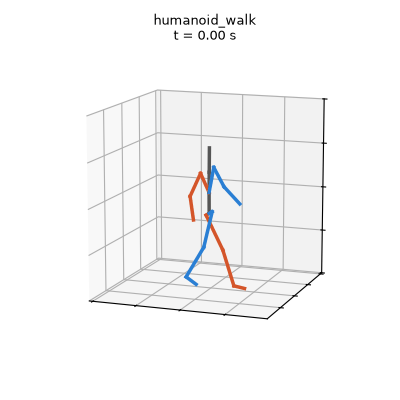

In [ ]:
A_VOIR = [
    ("humanoid_walk", 0.0),
    ("long/humanoid_long_walk0", 10.0),
    ("long/humanoid_long_walk0_mirror", 10.0),
    ("humanoid_run", 0.0),
    ("sie/humanoid_sie_run_forward00", 0.0),
    ("sie/humanoid_sie_run_forward14", 0.0),
    ("sie/humanoid_sie_run_left00", 0.0),
    ("sie/humanoid_sie_run_right07", 0.0),
]

for name, t0 in A_VOIR:
    display(Image(filename=animate(name, t0=t0)))

## 6. Rendu 3D, comme les figures de l'article

Les figures de l'article (Fig. 3, Fig. 6) montrent le personnage avec ses **formes de collision** : sphères pour
le bassin, le tronc et la tête, capsules pour les membres, boîtes pour les pieds. Ce sont exactement les
`<geom>` de `humanoid.xml`. On les fait dessiner par **MuJoCo**, le moteur physique qu'on utilisera ensuite
(`pip install mujoco`).

### 6.1 La scène

On n'édite pas `humanoid.xml` : on l'**inclut** dans une petite scène qui ajoute un sol quadrillé, un ciel
en dégradé, une lumière, et une couleur bleu-gris proche de celle de l'article.

In [ ]:
import mujoco
from PIL import Image as PILImage

SCENE_XML = f'''
<mujoco>
  <include file="{DATA / 'assets' / 'humanoid' / 'humanoid.xml'}"/>
  <visual>
    <headlight ambient=".5 .5 .5" diffuse=".45 .45 .45" specular=".1 .1 .1"/>
    <quality shadowsize="4096"/>
    <global offwidth="1600" offheight="600" fovy="25"/>
  </visual>
  <asset>
    <texture name="sky" type="skybox" builtin="gradient" rgb1=".93 .95 .97" rgb2=".62 .68 .74" width="512" height="512"/>
    <texture name="grid" type="2d" builtin="checker" rgb1=".92 .90 .85" rgb2=".88 .86 .81"
             mark="edge" markrgb=".78 .76 .71" width="512" height="512"/>
    <material name="floor" texture="grid" texrepeat="1 1" texuniform="true"/>
    <material name="skin" rgba=".42 .52 .66 1" specular=".35" shininess=".4"/>
  </asset>
  <worldbody>
    <light directional="true" pos="0 0 5" dir="-.3 .4 -1" diffuse=".5 .5 .5" castshadow="true"/>
    <geom name="floor" type="plane" size="0 0 .05" material="floor"/>
  </worldbody>
</mujoco>
'''

MODEL = mujoco.MjModel.from_xml_string(SCENE_XML)
skin = mujoco.mj_name2id(MODEL, mujoco.mjtObj.mjOBJ_MATERIAL, "skin")
for i in range(MODEL.ngeom):
    if MODEL.geom_bodyid[i] > 0:          # tous les geoms du personnage (le sol appartient au monde, corps 0)
        MODEL.geom_matid[i] = skin
        MODEL.geom_rgba[i] = MODEL.mat_rgba[skin]

print("nq =", MODEL.nq, "| articulations :", [MODEL.joint(i).name for i in range(MODEL.njnt)][:7], "...")

### 6.2 D'une frame de mocap à l'état MuJoCo (`qpos`)

MuJoCo décrit la pose par un vecteur `qpos` de **35** nombres, et non 34 :

| `qpos` | contenu | depuis la frame |
|---|---|---|
| 0-2 | position de la racine | colonnes 0-2, telles quelles |
| 3-6 | rotation de la racine en **quaternion** (w, x, y, z) | exponential map des colonnes 3-5, convertie |
| 7-34 | un angle par charnière (28) | voir ci-dessous |

Le point délicat, ce sont les articulations sphériques. Dans le MJCF, une épaule est faite de **3 charnières
successives** autour de x, puis y, puis z : sa rotation vaut $R = R_x(a)\,R_y(b)\,R_z(c)$, des angles d'Euler.
La mocap, elle, stocke une **exponential map**. Pour chaque articulation sphérique on calcule donc la matrice
$R$ depuis l'exponential map, puis on en extrait $(a, b, c)$.
Les articulations de révolution (genoux, coudes) se recopient directement.

On vérifie ensuite que les positions calculées par MuJoCo sont identiques à celles de notre
cinématique directe de la section 3.

In [ ]:
def euler_xyz(R):
    # angles (a, b, c) tels que R = Rx(a) Ry(b) Rz(c)
    b = np.arcsin(np.clip(R[..., 0, 2], -1.0, 1.0))
    a = np.arctan2(-R[..., 1, 2], R[..., 2, 2])
    c = np.arctan2(-R[..., 0, 1], R[..., 0, 0])
    return np.stack([a, b, c], axis=-1)


def frames_to_qpos(frames):
    T = len(frames)
    qpos = np.zeros((T, MODEL.nq))
    qpos[:, 0:3] = frames[:, 0:3]
    R_root = expmap_to_mat(frames[:, 3:6])
    for t in range(T):
        mujoco.mju_mat2Quat(qpos[t, 3:7], R_root[t].reshape(-1))
    k = 7
    for b in SKEL[1:]:
        if b["kind"] == "sphérique":
            qpos[:, k:k + 3] = euler_xyz(expmap_to_mat(frames[:, b["cols"]]))
            k += 3
        elif b["kind"] == "révolution":
            qpos[:, k] = frames[:, b["cols"].start]
            k += 1
    assert k == MODEL.nq
    return qpos


# Vérification sur 100 frames d'une longue marche
f = load_clip("long/humanoid_long_walk0")["frames"][::47]
qpos = frames_to_qpos(f)
pos_fk, _ = forward_kinematics(f)
body_ids = [mujoco.mj_name2id(MODEL, mujoco.mjtObj.mjOBJ_BODY, b["name"]) for b in SKEL]
data = mujoco.MjData(MODEL)
ecart = 0.0
for t in range(len(f)):
    data.qpos[:] = qpos[t]
    mujoco.mj_kinematics(MODEL, data)            # cinématique seule, pas de simulation
    ecart = max(ecart, np.abs(data.xpos[body_ids] - pos_fk[t]).max())
print(f"écart max entre MuJoCo et notre cinématique directe : {ecart:.1e} m")

L'écart est de l'ordre de la précision machine. MuJoCo et notre code lisent donc le squelette de la même
façon : mêmes offsets, même ordre des colonnes, mêmes axes.

### 6.3 Une « pellicule » façon Fig. 3

On superpose des poses prises à intervalle régulier dans une seule image (`mjv_addGeoms` ajoute les formes
d'un deuxième état à la scène déjà construite). La caméra regarde perpendiculairement à la direction principale
du déplacement.

In [ ]:
def camera_for(points, w, h, elevation=-10):
    # caméra fixe qui cadre une trajectoire du bassin (points : (N, 3))
    xy = points[:, :2] - points[:, :2].mean(0)
    direction = np.linalg.svd(xy, full_matrices=False)[2][0]       # axe principal du déplacement
    span = np.ptp(xy @ direction)
    depth = np.ptp(xy @ np.array([-direction[1], direction[0]]))
    hfov = 2 * np.arctan(np.tan(np.radians(MODEL.vis.global_.fovy) / 2) * w / h)
    cam = mujoco.MjvCamera()
    s = xy @ direction
    center = points[:, :2].mean(0) + direction * (s.min() + s.max()) / 2   # milieu de la trajectoire
    cam.lookat[:] = [*center, 0.8]
    vfov = np.radians(MODEL.vis.global_.fovy)
    cam.distance = max((span / 2 + 0.8) / np.tan(hfov / 2),   # toute la trajectoire en largeur
                       1.1 / np.tan(vfov / 2)) + depth / 2   # et le personnage (environ 2 m) en hauteur
    # Une trajectoire courbe : on place la caméra du côté convexe, pour que la courbe s'éloigne d'elle
    normal = np.array([-direction[1], direction[0]])                # la caméra est du côté +normal
    off = xy @ normal
    n = len(off)
    if off[n // 3: 2 * n // 3].mean() < 0.5 * (off[: n // 3].mean() + off[2 * n // 3:].mean()):
        direction = -direction
    cam.azimuth = np.degrees(np.arctan2(direction[1], direction[0])) - 90
    cam.elevation = elevation
    return cam


def filmstrip(name, t0, t1, pas, w=1600, h=420):
    clip = load_clip(name)
    idx = np.arange(int(t0 * clip["fps"]), min(int(t1 * clip["fps"]), len(clip["frames"])), int(pas * clip["fps"]))
    qpos = frames_to_qpos(clip["frames"][idx])
    states = []
    for q in qpos:
        d = mujoco.MjData(MODEL); d.qpos[:] = q; mujoco.mj_kinematics(MODEL, d); states.append(d)
    with mujoco.Renderer(MODEL, h, w) as r:
        r.update_scene(states[0], camera=camera_for(qpos[:, :3], w, h))
        for d in states[1:]:
            mujoco.mjv_addGeoms(MODEL, d, mujoco.MjvOption(), mujoco.MjvPerturb(), mujoco.mjtCatBit.mjCAT_DYNAMIC, r.scene)
        img = r.render()
    path = OUT / f"film_{name.split('/')[-1]}_{t0:g}s.png"
    PILImage.fromarray(img).save(path)
    return path


display(Image(filename=filmstrip("sie/humanoid_sie_run_forward14", 0.0, 4.0, 0.25)))
display(Image(filename=filmstrip("long/humanoid_long_walk0", 10.0, 14.0, 0.4, w=1000)))

### 6.4 Animation avec caméra qui suit le personnage

In [ ]:
def animate_3d(name, t0=0.0, duree=4.0, fps=30, w=480, h=360):
    clip = load_clip(name)
    idx = np.round((t0 + np.arange(0, duree, 1 / fps)) * clip["fps"]).astype(int)
    qpos = frames_to_qpos(clip["frames"][idx[idx < len(clip["frames"])]])
    cam = camera_for(qpos[:, :3], w, h)
    cam.distance = 4.0
    data = mujoco.MjData(MODEL)
    images = []
    with mujoco.Renderer(MODEL, h, w) as r:
        for q in qpos:
            data.qpos[:] = q
            mujoco.mj_kinematics(MODEL, data)
            cam.lookat[:2] = q[:2]                       # la caméra suit le bassin
            r.update_scene(data, camera=cam)
            images.append(PILImage.fromarray(r.render()))
    path = OUT / f"3d_{name.split('/')[-1]}_{t0:g}s.gif"
    images[0].save(path, save_all=True, append_images=images[1:], duration=1000 / fps, loop=0)
    return path


for name, t0 in A_VOIR:
    display(Image(filename=animate_3d(name, t0=t0)))